In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import LabelEncoder

In [2]:
def show_rgb_image(image, title=None, conversion=cv2.COLOR_BGR2RGB):

    # Converts from one colour space to the other. this is needed as RGB
    # is not the default colour space for OpenCV
    image = cv2.cvtColor(image, conversion)

    # Show the image
    plt.imshow(image)

    # remove the axis / ticks for a clean looking image
    plt.xticks([])
    plt.yticks([])

    # if a title is provided, show it
    if title is not None:
        plt.title(title)

    plt.show()

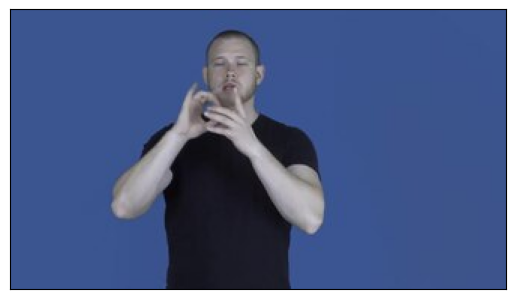

In [3]:
img_path = "../data/train/people/330px-Deaf_vs_deaf.webm.jpg"

img = cv2.imread(img_path)

show_rgb_image(img)


In [4]:
win_size = (512, 512)

In [5]:
def load_split(split_name, max_samples_per_class=None):
    """
    Load images and labels from a folder (train/test).
    Dynamically reads all subfolders (classes).
    """
    split_dir = Path("../data") / split_name
    if not split_dir.exists():
        split_dir = Path("data") / split_name
    if not split_dir.exists():
        raise FileNotFoundError(f"Split directory not found: {split_dir}")

    # Discover all object label subfolders
    classes = sorted([d.name for d in split_dir.iterdir() if d.is_dir()])
    
    images = []
    labels = []

    for cls_name in classes:
        cls_folder = split_dir / cls_name
        files = sorted(list(cls_folder.glob("*.jpg")) + list(cls_folder.glob("*.jpeg")))
        if max_samples_per_class:
            files = files[:max_samples_per_class]

        for file_path in files:
            img_item = cv2.imread(str(file_path))
            if img_item is not None:
                img_resized = cv2.resize(img_item, win_size)
                images.append(img_resized)
                labels.append(cls_name)

    return np.array(images), np.array(labels), classes

X_train_images, y_train, classes = load_split("train")
X_test_images, y_test, _ = load_split("test")

print(f"Discovered Classes: {classes}")
print(f"Training samples:   {len(X_train_images)} images")
print(f"Test samples:       {len(X_test_images)} images")


Discovered Classes: ['apples', 'dogs', 'people']
Training samples:   523 images
Test samples:       140 images


In [ ]:
block_size = (64, 64)
block_stride = (32, 32)
cell_size = (32.ven.....aa, 32)
nbins = 9
derivA = 1
win_sigma = -1
histogram_norm_type = 0
L2_hys_threshold = 0.2
gamma_correction = True
nlevels = 64
signed_gradient = True

hog = cv2.HOGDescriptor(
    win_size,
    block_size,
    block_stride,
    cell_size,
    nbins,
    derivA,
    win_sigma,
    histogram_norm_type,
    L2_hys_threshold,
    gamma_correction,
    nlevels,
    signed_gradient
)


In [7]:
img_resized = cv2.resize(img, win_size)
des = hog.compute(cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY))

print(f"HOG Descriptor shape: {des.shape}")


HOG Descriptor shape: (8100,)


In [8]:
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
X_train = np.array([hog.compute(cv2.cvtColor(img_item, cv2.COLOR_BGR2GRAY)).flatten() for img_item in X_train_images])


In [9]:
svm = cv2.ml.SVM_create()
svm.setType(cv2.ml.SVM_C_SVC)
svm.setKernel(cv2.ml.SVM_RBF)

# 1. Format samples: 2D matrix of shape (N, feature_dim) as float32
samples = X_train.reshape(len(X_train_images), -1).astype(np.float32)

# 2. Format labels: 2D column vector of shape (N, 1) as int32
responses = y_train_encoded.reshape(-1, 1).astype(np.int32)

# Train using automated hyperparameter grid search
svm.trainAuto(samples, cv2.ml.ROW_SAMPLE, responses)

# 3. Save model using standard Python dot notation
svm.save("hog_svm_model.yml")

# 4. Load model using standard Python dot notation
#svm = cv2.ml.SVM_load("hog_svm_model.yml")


In [10]:
# Format example as 2D float32 array: shape (1, num_features)
example = des.reshape(1, -1).astype(np.float32)

# Validate feature count against SVM model expectation
var_count = svm.getVarCount()
if example.shape[1] != var_count:
    raise ValueError(f"Feature mismatch: model expects {var_count} features, but got {example.shape[1]}.")

testResponse = svm.predict(example)[1]

predicted_class = int(testResponse[0, 0])
predicted_name = le.inverse_transform([predicted_class])[0]

print(f"Predicted class name: {predicted_name}")


Predicted class name: people


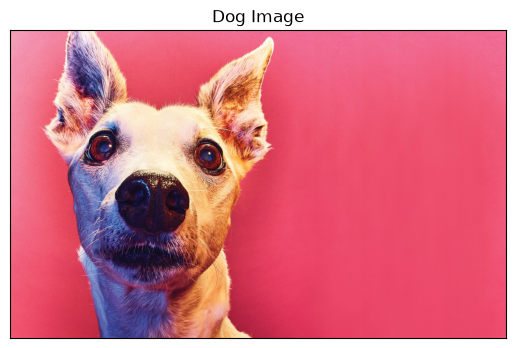

Predicted class name for dog image: 2 people


In [11]:
dogImg = cv2.imread("../data/test/dogs/dog_28.jpg")

show_rgb_image(dogImg, title="Dog Image")

dogResize = cv2.resize(dogImg, win_size)
dogDes = hog.compute(cv2.cvtColor(dogResize, cv2.COLOR_BGR2GRAY)).reshape(1, -1).astype(np.float32)
dogResponse = svm.predict(dogDes)[1]

predicted_class = int(dogResponse[0, 0])
predicted_name = le.inverse_transform([predicted_class])[0]

print(f"Predicted class name for dog image: {predicted_class} {predicted_name}")